# 07 — How the optimum moves with idle-noise strength, and why

Across idle strengths, with gates held fixed: does Δt* follow the
scaling the paper's ansatz implies, and where does waiting stop paying?

**Source:** `python -m qec_timing.studies.idle_scaling --placement uniform` →
`results/idle_scaling/idle_scaling_uniform.json`. Textbook gates, idle noise on every qubit
during each layer and the wait (as in notebook 04), X basis, H2 ratios scaled to
p2 = 5×10⁻³, T = 192, 2 × 100k shots per point. Linear γ/p2 ∈ {0.15, 0.3, 0.6},
quadratic c/p2 ∈ {0.0025, 0.01, 0.04}. The ansatz R = (A/Δt)(1 + q(Δt)/p_e)^α is fitted per
distance to all six curves and then predicts Δt* for any idle error per round.

**Definitions.** Time is in units of t_R; one logical qubit (a single surface-code patch).
Idle noise is identical on every physical qubit, so these are per-qubit numbers computed from
(γ, c), not measured.

- One idle chunk of duration τ flips a qubit (Z) with probability
  p(τ) = γτ ⊕ sin²(√c·τ),  where a ⊕ b = a + b − 2ab (an odd number of flips).
- One period of the circuit is 7 layers of 1/7 each (one chunk after each) plus a wait of
  Δt − 1 (one chunk). Each chunk is twirled on its own, so the quadratic term restarts in
  every chunk. The idle error per period is
  q(Δt) = ½·[1 − (1 − 2·p(1/7))⁷ · (1 − 2·p(Δt − 1))].
- Idle error per round (the x-axis of the second figure): q(1) = ½·[1 − (1 − 2·p(1/7))⁷],
  ≈ γ for linear idle and ≈ 7·sin²(√c/7) ≈ c/7 for quadratic idle (not sin²(√c) ≈ c).
- Ansatz (the paper's Eq. 5 with λΔt → q(Δt)/p_e): R(Δt) = (A/Δt)·(1 + q(Δt)/p_e)^α,
  with A, p_e, α fitted per distance to all six curves; Δt* is its first local minimum.
- Idle on the ancillas (which acts like readout error) is not in the ansatz.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
isc = json.loads((R / "idle_scaling" / "idle_scaling_uniform.json").read_text())
ref = json.loads((R / "idle_scaling" / "idle_scaling.json").read_text())   # data-only idle
for r in isc["rows"]:
    s, f = r["slopes"], r["ansatz"]
    print(f"d={r['d']}: slope linear {s['lin']['slope']:.3f} ± {s['lin']['se']:.3f} (predicted -1), "
          f"quadratic {s['quad']['slope']:.3f} ± {s['quad']['se']:.3f} (predicted -0.5);  "
          f"alpha {f['alpha']:.2f} ± {f['alpha_se']:.2f} -> g = {f['implied_g']:.2f} (paper 0.8)")

d=3: slope linear -0.997 ± 0.020 (predicted -1), quadratic -0.495 ± 0.010 (predicted -0.5);  alpha 1.45 ± 0.02 -> g = 0.73 (paper 0.8)
d=5: slope linear -1.040 ± 0.020 (predicted -1), quadratic -0.493 ± 0.010 (predicted -0.5);  alpha 1.75 ± 0.03 -> g = 0.58 (paper 0.8)
d=7: slope linear -1.052 ± 0.020 (predicted -1), quadratic -0.476 ± 0.010 (predicted -0.5);  alpha 1.95 ± 0.05 -> g = 0.49 (paper 0.8)


In [3]:
# Idle on every qubit against idle on the data only (the original repo's setup), same seeds.
print(f"{'d':>2} {'idle':<12}{'data only':>10}{'every qubit':>13}{'change':>8}")
for r, r0 in zip(isc["rows"], ref["rows"]):
    pairs = [(f"{c['family']} {c['value']:g}", c0["optimum"]["dt_star"], c["optimum"]["dt_star"])
             for c, c0 in zip(r["curves"], r0["curves"])]
    pairs.append(("mixed (held)", r0["held_out"]["optimum"]["dt_star"], r["held_out"]["optimum"]["dt_star"]))
    for lab, a, b in pairs:
        print(f"{r['d']:>2} {lab:<12}{a:>10.2f}{b:>13.2f}{b / a - 1:>+8.0%}")

 d idle         data only  every qubit  change
 3 lin 0.15         19.70        20.47     +4%
 3 lin 0.3           9.64        10.12     +5%
 3 lin 0.6           4.54         5.14    +13%
 3 quad 0.0025      16.65        17.05     +2%
 3 quad 0.01         8.05         8.25     +2%
 3 quad 0.04         4.05         4.32     +7%
 3 mixed (held)      5.10         5.50     +8%
 5 lin 0.15         10.89        11.25     +3%
 5 lin 0.3           5.12         5.35     +5%
 5 lin 0.6           2.49         2.66     +7%
 5 quad 0.0025      14.27        14.48     +1%
 5 quad 0.01         6.77         7.19     +6%
 5 quad 0.04         3.37         3.69     +9%
 5 mixed (held)      3.55         3.80     +7%
 7 lin 0.15          7.13         7.32     +3%
 7 lin 0.3           3.38         3.49     +3%
 7 lin 0.6           1.64         1.70     +4%
 7 quad 0.0025      12.25        12.47     +2%
 7 quad 0.01         6.01         6.59    +10%
 7 quad 0.04         2.88         3.34    +16%
 7 mixed (hel

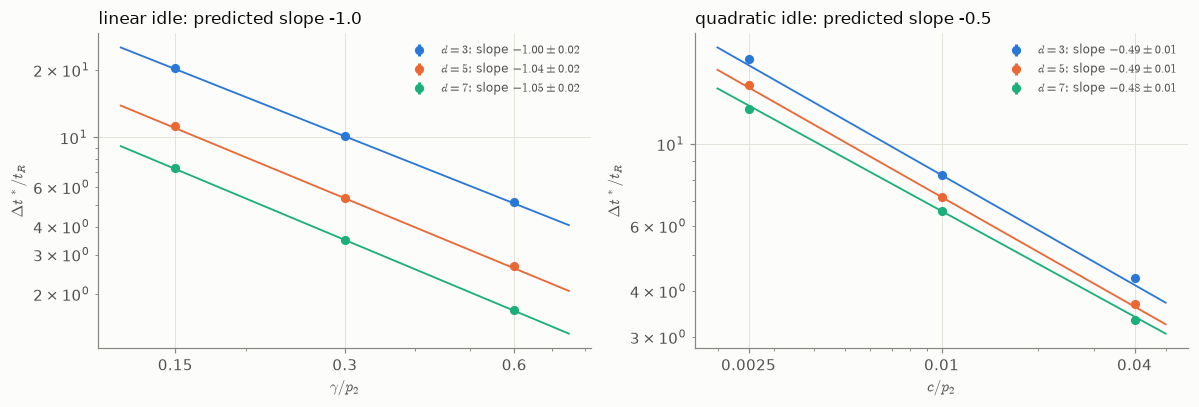

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, fam, xlab, pred in ((axes[0], "lin", r"$\gamma / p_2$", -1.0), (axes[1], "quad", r"$c / p_2$", -0.5)):
    for r in isc["rows"]:
        cs = [c for c in r["curves"] if c["family"] == fam]
        x = np.array([c["value"] for c in cs]); y = np.array([c["optimum"]["dt_star"] for c in cs])
        lo = y - np.array([c["optimum"]["lo"] for c in cs]); hi = np.array([c["optimum"]["hi"] for c in cs]) - y
        ax.errorbar(x, y, yerr=[lo, hi], fmt="o", color=P.D_COLOR[r["d"]], ms=5,
                    label=rf"$d = {r['d']}$: slope ${r['slopes'][fam]['slope']:.2f} \pm {r['slopes'][fam]['se']:.2f}$")
        m = r["slopes"][fam]["slope"]; xs = np.geomspace(x.min() * 0.8, x.max() * 1.25, 20)
        ax.plot(xs, y[1] * (xs / x[1]) ** m, "-", color=P.D_COLOR[r["d"]], lw=1.2)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.legend(fontsize=8)
    ax.set_xticks(x, [f"{v:g}" for v in x]); ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel(xlab); ax.set_ylabel(r"$\Delta t^* / t_R$")
    ax.set_title(f"{'linear' if fam == 'lin' else 'quadratic'} idle: predicted slope {pred}", loc="left")
fig.tight_layout()
P.save(fig, "07_dt_star_vs_idle_strength_1")

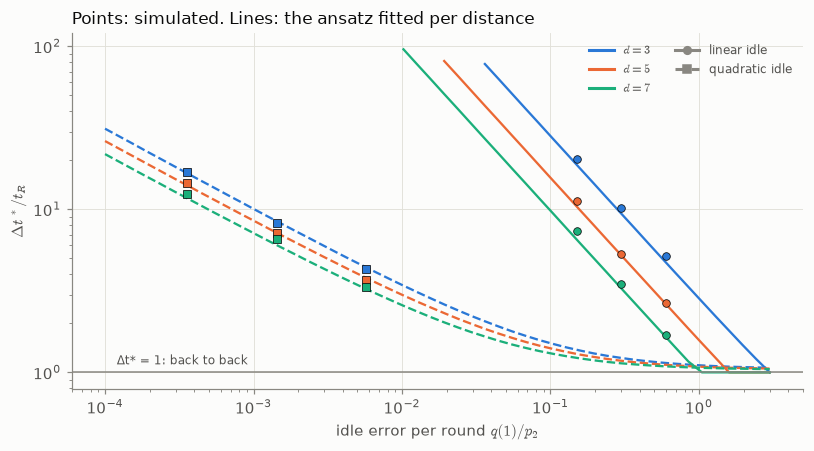

In [5]:
from qec_timing.studies.idle_scaling import q_idle
place, p2, T_ = isc["setup"]["placement"], isc["setup"]["p2"], isc["setup"]["T"]
from matplotlib.lines import Line2D
fig, ax = plt.subplots(figsize=(7.5, 4.2))
LS = {"lin": ("-", "o", "linear idle"), "quad": ("--", "s", "quadratic idle")}
for r in isc["rows"]:
    col = P.D_COLOR[r["d"]]
    for fam, (ls, mk, _) in LS.items():
        F = [q for q in r["formula"][fam] if q["dt_star"] < T_ / 2]      # inside a run of T = 192 t_R
        ax.plot([q["q_over_p2"] for q in F], [q["dt_star"] for q in F], ls, color=col, lw=1.5)
        cs = [c for c in r["curves"] if c["family"] == fam]
        q1 = [float(q_idle(1.0, *((c["value"] * p2, 0.0) if fam == "lin" else (0.0, c["value"] * p2)), place)) / p2
              for c in cs]
        ax.plot(q1, [c["optimum"]["dt_star"] for c in cs], mk, color=col, ms=5, mec=P.INK, mew=0.5)
ax.axhline(1, color=P.MUTED, lw=1); ax.text(1.2e-4, 1.12, "Δt* = 1: back to back", color=P.INK_2, fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"idle error per round $q(1) / p_2$"); ax.set_ylabel(r"$\Delta t^* / t_R$")
h = [Line2D([], [], color=P.D_COLOR[r["d"]], lw=2, label=P.dl(r["d"])) for r in isc["rows"]]
h += [Line2D([], [], color=P.MUTED, ls=ls, marker=mk, label=lab) for ls, mk, lab in LS.values()]
ax.legend(handles=h, fontsize=8, ncol=2)
ax.set_title("Points: simulated. Lines: the ansatz fitted per distance", loc="left")
fig.tight_layout()
P.save(fig, "07_dt_star_vs_idle_strength_2")

**Reading.**
- *Measured:* Δt* follows the power laws the ansatz implies: slopes −1.00, −1.04, −1.05 (± 0.02)
  for linear idle against −1, and −0.49, −0.49, −0.48 (± 0.01) for quadratic against −0.5, at
  d = 3, 5, 7. At d = 5 and 7 the linear slopes are 2–2.6σ steeper than predicted; each line
  has three points.
- *Measured:* idle on every qubit lengthens Δt* by 1–16% against idle on the data only (the
  original repo's setup, table above), most for strong quadratic idle at d = 7.
- *Measured:* with q(Δt) composed as the circuit applies it, the ansatz fits with χ²/dof = 16,
  37, 97 at d = 3, 5, 7 (statistical errors only, ~0.5% per point). The misfit grows with d;
  idle on the ancillas, which the ansatz does not represent, is the likely remainder.
- *Measured:* the fitted α corresponds to g = 0.73, 0.58, 0.49, below the paper's 0.8 and
  falling with d, unlike the paper's model (notebook 02), where g rises towards 0.8.
- *Interp.:* the lines run far outside the simulated points (q(1)/p2 ≈ 4×10⁻⁴ to 0.6): read
  them as extrapolation. Δt* cannot fall below 1 (the wait cannot be negative), so it
  approaches back to back rather than crossing it.

## Where waiting pays, over the whole idle plane

The calibrated ansatz's Δt* over the plane of linear and quadratic idle strength, per distance.
Inside the dashed box simulations exist (the six fitted curves sit on its edges); outside it
the formula is extrapolated (pale). The white line is where an optimised interval buys less
than 5% over back to back (gain R(1)/R(Δt*) = 1.05); beyond it, waiting is not worth it.
The star is a simulation with **both** idle terms that was held out of the fit, the test of
the formula. The dark line is H2-1E's emulator idle rates for round durations t_R from 1 to
300 ms: the device's position in this plane is set by t_R (γ/p2 ∝ t_R, c/p2 ∝ t_R²).

*Assumption:* the axes are idle strength relative to p2, so the map built at scaled gates
(p2 = 5×10⁻³) is read at H2's own p2; notebook 07 of the original repo checked that halving
all rates leaves Δt* unchanged.

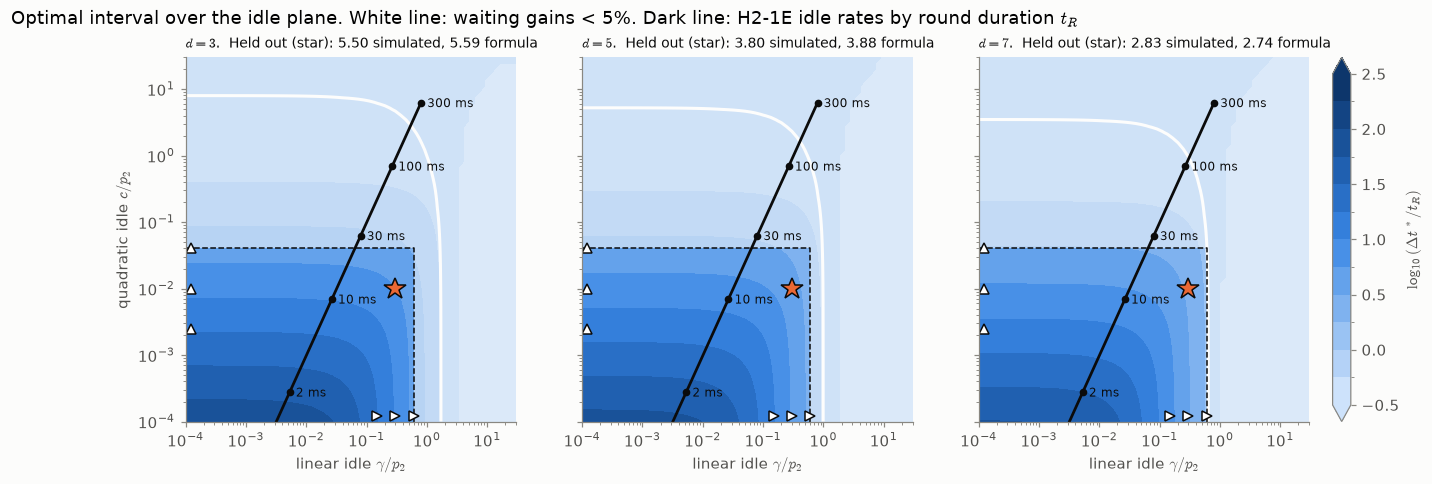

In [6]:
import math
from matplotlib.colors import BoundaryNorm
cal = json.loads((Path("..") / "config" / "h2_1e_emulator.json").read_text())
omega = 2 * math.pi * cal["quad_rate"] * cal["quad_factor"]          # "cycles" reading
tR = np.geomspace(1e-3, 0.3, 60)
h2_g = cal["gamma"] * tR / cal["p2"]; h2_c = (omega * tR / 2) ** 2 / cal["p2"]
fig, axes = plt.subplots(1, len(isc["rows"]), figsize=(4.6 * len(isc["rows"]), 4.3), sharey=True)
levels = np.arange(-0.5, 2.51, 0.25)
cmap = P.sequential_cmap(); norm = BoundaryNorm(levels, cmap.N)
lin, quad = isc["setup"]["lin"], isc["setup"]["quad"]
for ax, r in zip(np.atleast_1d(axes), isc["rows"]):
    ax_ = np.array(r["map"]["axis"]); Z = np.log10(np.array(r["map"]["dt_star"]))
    cs = ax.contourf(ax_, ax_, Z, levels=levels, cmap=cmap, norm=norm, extend="both")
    G = np.array(r["map"]["gain"])
    ax.contour(ax_, ax_, G, levels=[1.05], colors="white", linewidths=2)
    # extrapolated region: everything outside the simulated box
    box = (min(lin), max(lin), min(quad), max(quad))
    from matplotlib.patches import Rectangle
    for x0, y0, x1, y1 in ((box[1], ax_[0], ax_[-1], ax_[-1]), (ax_[0], box[3], box[1], ax_[-1])):
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, color=P.SURFACE, alpha=0.55, lw=0, zorder=2))
    ax.plot([ax_[0], box[1], box[1]], [box[3], box[3], ax_[0]], "--", color=P.INK, lw=1)
    ax.plot(lin, [ax_[1]] * 3, ">", color="white", mec=P.INK, ms=7)
    ax.plot([ax_[1]] * 3, quad, "^", color="white", mec=P.INK, ms=7)
    h = r["held_out"]
    ax.plot(h["gamma_over_p2"], h["c_over_p2"], "*", color=P.SERIES[1], mec=P.INK, ms=15)

    ax.plot(h2_g, h2_c, "-", color=P.INK, lw=1.8)
    for t in (2e-3, 1e-2, 3e-2, 0.1, 0.3):
        g_, c_ = cal["gamma"] * t / cal["p2"], (omega * t / 2) ** 2 / cal["p2"]
        if g_ > ax_[0] and c_ > ax_[0]:
            ax.plot(g_, c_, "o", color=P.INK, ms=4)
            ax.annotate(f"{t*1e3:g} ms", (g_, c_), xytext=(4, -3), textcoords="offset points", fontsize=8, color=P.INK)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(False)
    ax.set_xlim(ax_[0], ax_[-1]); ax.set_ylim(ax_[0], ax_[-1])
    ax.set_xlabel(r"linear idle $\gamma / p_2$")
    ax.set_title(rf"$d = {r['d']}$.  Held out (star): {h['optimum']['dt_star']:.2f} simulated, {h['formula_dt_star']:.2f} formula",
                 loc="left", fontsize=9)
np.atleast_1d(axes)[0].set_ylabel(r"quadratic idle $c / p_2$")
fig.colorbar(cs, ax=axes, label=r"$\log_{10}(\Delta t^* / t_R)$", fraction=0.025, pad=0.02)
fig.suptitle(r"Optimal interval over the idle plane. White line: waiting gains < 5%. Dark line: H2-1E idle rates by round duration $t_R$", x=0.01, ha="left")
P.save(fig, "07_dt_star_vs_idle_strength_3")

**Reading.**
- *Measured:* the held-out simulation (both idle terms at once) is predicted to within 1.6%,
  2.1% and 3.2% (Δt* 5.50, 3.80, 2.83 simulated against 5.59, 3.88, 2.74 at d = 3, 5, 7);
  inside the box the map is a calibrated prediction, not just a fit.
- *Interp.:* along H2-1E's trajectory the formula gives a gain of ×30–45 at t_R = 1 ms and
  ×1.6–2.1 at 30 ms; the gain falls below 5% from t_R ≈ 120 ms (d = 7), 150 ms (d = 5) and
  200 ms (d = 3). These points lie outside the box: a fitted formula at scaled gates,
  extrapolated, not a simulation at H2's own rates.
- *Limits:* outside the box (pale) the formula is extrapolated; the quadratic search stops at
  the term's first maximum, where the twirled model stops describing decoherence.

## The same map on physical axes: round duration and dephasing strength

The map above is in per-round units, which mixes the device with its round duration: a device
with fixed idle rates moves along a slope-2 line as t_R changes. Here the same calibrated formula
is evaluated on physical axes instead. Top row: x = round duration t_R, y = the qubit frequency
offset f = ω/2π that sets the quadratic term sin²(ωt/2), with the linear rate fixed at H2-1E's
γ = 2.8×10⁻³ s⁻¹. Bottom row: y = the linear rate γ, with f fixed at H2-1E's (86 mHz, the
"cycles" reading of the emulator's quadratic rate). Per round, γ_R = γ·t_R and c = (ω·t_R/2)²,
both read relative to H2's p2 = 1.05×10⁻³ (the same scale assumption as above).

Overlays: H2-1E's emulator value (dashed line); the typical frequency offset Quantinuum quotes
for H2, ≈ 75 mHz ([DD docs](https://docs.quantinuum.com/systems/trainings/h2/getting_started/dd.html));
the dashed outline encloses the simulated region; the grey band is an *estimate* of a surface-code
round on current H2, ~100–250 ms: 4 CX layers plus measurement at a depth-one circuit time of
~60–68 ms (arXiv:2409.04628, 2506.14169), and ~200 ms per round reported for H1's colour code
(arXiv:2208.08064). It is not a measured surface-code t_R.

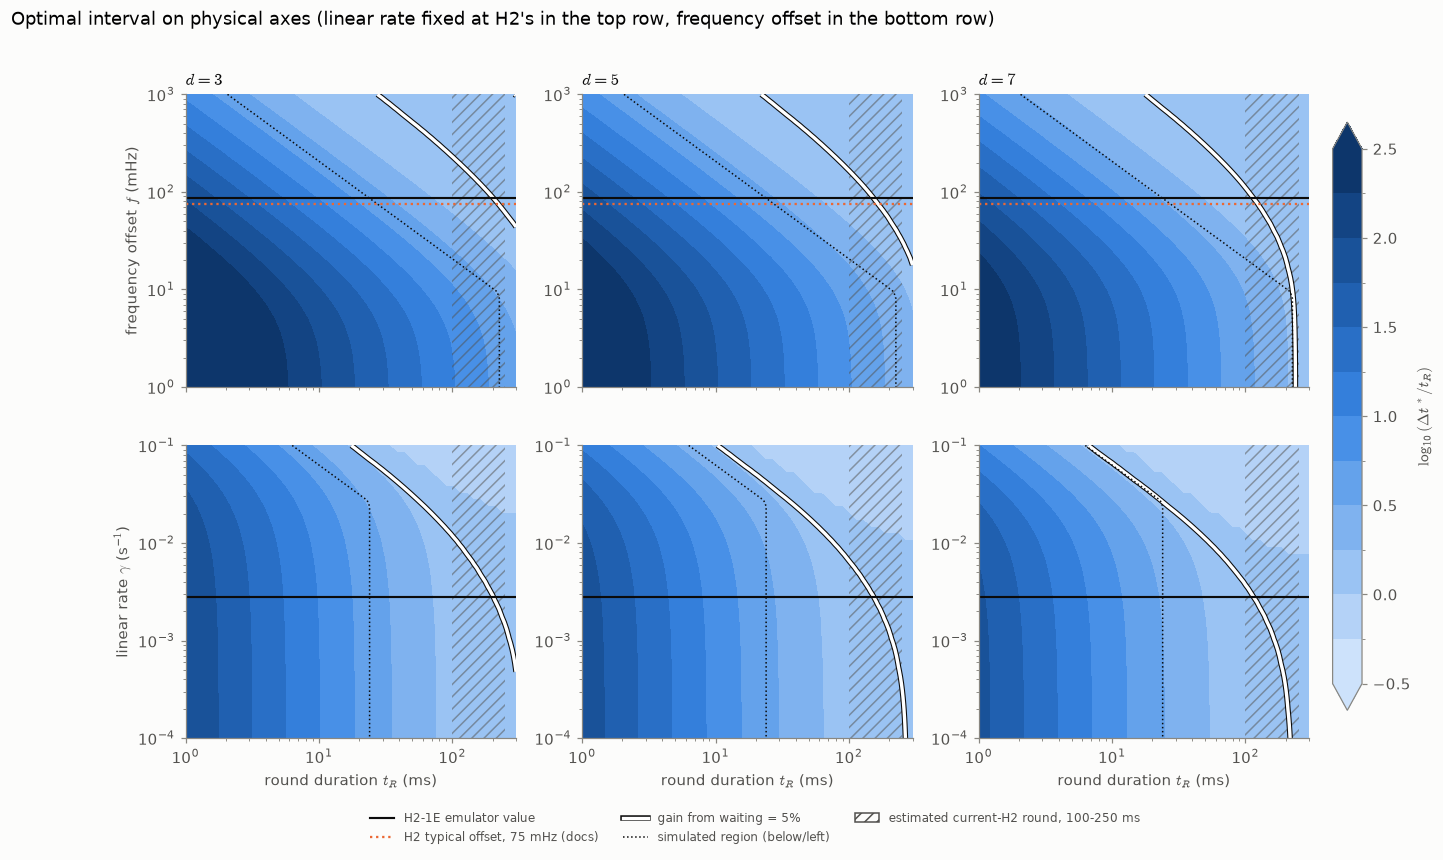

In [7]:
import matplotlib.patheffects as pe
from qec_timing.studies.idle_scaling import dt_star_gc, gain_gc
P2_SIM, p2_dev = isc["setup"]["p2"], cal["p2"]
f_h2 = omega / (2 * math.pi)                                       # Hz
tR_ax = np.geomspace(1e-3, 0.3, 48)                                # s
f_ax = np.geomspace(1e-3, 1.0, 44)                                 # Hz
g_ax = np.geomspace(1e-4, 1e-1, 44)                                # 1/s
box = (max(isc["setup"]["lin"]), max(isc["setup"]["quad"]))        # simulated: gamma/p2, c/p2 upper edges

def per_round(gamma, f, t):
    """(gamma_R / p2, c / p2) per round for physical rates gamma [1/s], f [Hz] at round time t [s]."""
    return gamma * t / p2_dev, (2 * math.pi * f * t / 2) ** 2 / p2_dev

def grids(fit, ys, kind):
    D = np.empty((len(ys), len(tR_ax))); G = np.empty_like(D); S = np.empty_like(D)
    for i, y in enumerate(ys):
        for j, t in enumerate(tR_ax):
            g, c = per_round(cal["gamma"], y, t) if kind == "f" else per_round(y, f_h2, t)
            D[i, j] = dt_star_gc(g * P2_SIM, c * P2_SIM, fit, place)
            G[i, j] = gain_gc(g * P2_SIM, c * P2_SIM, fit, place)
            S[i, j] = max(g / box[0], c / box[1])                  # <= 1: inside the simulated region
    return D, G, S

fig, axes = plt.subplots(2, len(isc["rows"]), figsize=(4.6 * len(isc["rows"]), 7.6), sharex=True)
for col, r in enumerate(isc["rows"]):
    for row, (ys, kind, h2y, ylab) in enumerate(((f_ax, "f", f_h2, "frequency offset $f$ (mHz)"),
                                                 (g_ax, "g", cal["gamma"], r"linear rate $\gamma$ (s$^{-1}$)"))):
        ax = axes[row, col]
        D, G, S = grids(r["ansatz"], ys, kind)
        yplot = ys * 1e3 if kind == "f" else ys
        cs = ax.contourf(tR_ax * 1e3, yplot, np.log10(D), levels=levels, cmap=cmap, norm=norm, extend="both")
        ax.contour(tR_ax * 1e3, yplot, G, levels=[1.05], colors="white", linewidths=2.2,
                   path_effects=[pe.Stroke(linewidth=3.6, foreground=P.INK), pe.Normal()])
        ax.contour(tR_ax * 1e3, yplot, S, levels=[1.0], colors=P.INK, linewidths=1, linestyles=":")
        ax.axvspan(100, 250, facecolor="none", edgecolor=P.INK_2, hatch="///", lw=0, alpha=0.5)
        ax.axhline(h2y * (1e3 if kind == "f" else 1), color=P.INK, ls="-", lw=1.4)
        if kind == "f":
            ax.axhline(75, color=P.SERIES[1], ls=":", lw=1.5)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(False)
        if row == 0:
            ax.set_title(rf"$d = {r['d']}$", loc="left")
        if row == 1:
            ax.set_xlabel(r"round duration $t_R$ (ms)")
        if col == 0:
            ax.set_ylabel(ylab)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
h = [Line2D([], [], color=P.INK, ls="-", lw=1.4, label="H2-1E emulator value"),
     Line2D([], [], color=P.SERIES[1], ls=":", lw=1.5, label="H2 typical offset, 75 mHz (docs)"),
     Line2D([], [], color="white", lw=2.2, label="gain from waiting = 5%",
            path_effects=[pe.Stroke(linewidth=3.6, foreground=P.INK), pe.Normal()]),
     Line2D([], [], color=P.INK, ls=":", lw=1, label="simulated region (below/left)"),
     Patch(facecolor="none", edgecolor=P.INK_2, hatch="///", label="estimated current-H2 round, 100-250 ms")]
fig.legend(handles=h, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.03))
fig.colorbar(cs, ax=axes, label=r"$\log_{10}(\Delta t^* / t_R)$", fraction=0.025, pad=0.02)
fig.suptitle("Optimal interval on physical axes (linear rate fixed at H2's in the top row, frequency offset in the bottom row)",
             x=0.01, ha="left")
P.save(fig, "07_dt_star_vs_idle_strength_4")

**Reading.**
- *Interp.:* each point is a device and a round duration; the white line separates "wait" (left,
  below) from "back to back" (right, above). Faster rounds or weaker dephasing move a device left
  or down, where waiting pays.
- *Interp.:* at H2's dephasing (solid line) the white line is crossed at t_R ≈ 200, 160 and
  120 ms for d = 3, 5, 7, inside the estimated current-H2 round (hatched): on today's hardware
  the optimal interval is expected to buy little. Large gains need rounds of order 1–10 ms, or
  weaker dephasing; the x-axis tells how much faster rounds would have to be.
- *Limits:* the same as the map above: outside the dashed outline the formula is extrapolated,
  the scale assumption reads results at p2 = 5×10⁻³ on H2's p2, and the grey band is an estimate
  from published layer times, not a measured surface-code round.